# 04 · Project Summary: Procurement-Failure Risk for PhilGEPS Public Biddings

**PhilGEPS procurement-failure risk · Summary of notebooks 00–03**

This notebook is **auto-updating**. It contains no hand-typed results: every number, table, chart and finding below is computed, when the notebook runs, from the outputs of the pipeline:

| Input | Written by |
|---|---|
| cleaning counts (saved outputs of notebook 00) | `00_data_cleaning.ipynb` |
| `data/processed/philgeps_cleaned.parquet` | `scripts/harmonise_cleaned.py` |
| `data/processed/bids_public_bidding.parquet`, exceptions log | `01_data_preparation_and_eda.ipynb` |
| split assignment, final model, `models/*.csv`, `final_config.json` | `02_modeling.ipynb` |
| `models/diagnostics_*.csv` | `03_diagnostics_and_interpretation.ipynb` |

To refresh it, re-run the pipeline and then this notebook. `python scripts/run_pipeline.py` does both in order.

**Contents:** 1. Problem · 2. Data · 3. Methodology · 4. Key findings · 5. Business applications · 6. Limitations and next steps

In [1]:
import json
import re
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Markdown, display
from sklearn.metrics import confusion_matrix, f1_score, matthews_corrcoef

import procurement_failure as pf

pd.set_option("display.width", 200)

def md(text):
    display(Markdown(text))

def n(x):
    return f"{int(round(x)):,}"

def pct(x, digits=1):
    return f"{x * 100:.{digits}f}%"

# Chart tokens: one series hue, a neutral reference line, recessive chrome, text in ink colours.
SERIES, REFERENCE, SURFACE, INK, INK_2, GRID = "#2a78d6", "#52514e", "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"

# Readable names for the model inputs.
FEATURE_LABELS = {
    "log_approved_budget": "Approved budget", "bidding_window_days": "Bidding window (days)",
    "log_n_line_items": "Number of line items", "log_contract_duration_days": "Contract duration",
    "multi_funding_source": "More than one funding source", "published_month": "Publication month",
    "published_dayofweek": "Publication weekday", "PE Organization Type (Grouped)": "Organisation type",
    "Trade Agreement": "Procurement rules", "Business Category": "Procurement category",
}
def label(feature):
    return FEATURE_LABELS.get(feature, feature)

def style(ax):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_2, length=0)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)

# ---- Load every pipeline output (fail with a clear message if a step has not been run).
required = {
    "cleaned data (harmonise_cleaned.py)": pf.CLEANED,
    "bid table (notebook 01)": pf.BIDS,
    "exceptions log (notebook 01)": pf.EXCEPTIONS,
    "split assignment (notebook 02)": pf.SPLITS,
    "final model (notebook 02)": pf.MODELS / "final_calibrated.joblib",
    "final configuration (notebook 02)": pf.MODELS / "final_config.json",
    "validation results (notebook 02)": pf.MODELS / "validation_results.csv",
    "sensitivity results (notebook 02)": pf.MODELS / "sensitivity_failed_only.csv",
    "diagnostics (notebook 03)": pf.MODELS / "diagnostics_out_of_time.csv",
}
missing = [name for name, path in required.items() if not path.exists()]
if missing:
    raise FileNotFoundError("Run the pipeline first. Missing: " + "; ".join(missing))

bids = pd.read_parquet(pf.BIDS)
exceptions = pd.read_csv(pf.EXCEPTIONS)
splits = pd.read_parquet(pf.SPLITS)
config = json.loads((pf.MODELS / "final_config.json").read_text())
calibrated = joblib.load(pf.MODELS / "final_calibrated.joblib")
validation = pd.read_csv(pf.MODELS / "validation_results.csv")
sensitivity = pd.read_csv(pf.MODELS / "sensitivity_failed_only.csv")
diag = {name: pd.read_csv(pf.MODELS / f"diagnostics_{name}.csv")
        for name in ["out_of_time", "drift", "label_coverage", "permutation_importance", "budget_deciles",
                     "adjusted_curves", "risk_deciles", "scores_by_status"]}

for c in pf.KEY:
    bids[c] = bids[c].astype(str); splits[c] = splits[c].astype(str)
labelled = bids[bids.Target_Failed.notna()].merge(splits, on=pf.KEY, how="left")
test = labelled[labelled.split == "test"].copy()
numeric, categorical = config["numeric"], config["categorical"]
test["prob"] = calibrated.predict_proba(pf.model_frame(test, numeric, categorical))[:, 1]
y_test = test.Target_Failed.astype(int).to_numpy()
prob_test = test.prob.to_numpy()

# ---- Cleaning counts, read from the saved outputs of notebook 00.
nb00 = nbformat.read(pf.ROOT / "notebooks" / "00_data_cleaning.ipynb", as_version=4)
nb00_text = "\n".join(o.get("text", "") for c in nb00.cells if c.cell_type == "code" for o in c.get("outputs", []))
def from_nb00(pattern):
    m = re.search(pattern, nb00_text)
    return int(m.group(1).replace(",", "")) if m else None
cleaning = {
    "files": from_nb00(r"Successfully loaded (\d+) of"),
    "raw_rows": from_nb00(r"Rows before: ([\d,]+)"),
    "duplicates": from_nb00(r"Duplicate rows dropped: ([\d,]+)"),
    "closed": from_nb00(r"Closed-status rows dropped: ([\d,]+)"),
    "remaining": from_nb00(r"Rows remaining: ([\d,]+)"),
}
cleaned_rows = pq.ParquetFile(pf.CLEANED).metadata.num_rows

inputs = [pf.CLEANED, pf.BIDS, pf.MODELS / "final_config.json", pf.MODELS / "diagnostics_out_of_time.csv"]
newest = max(datetime.fromtimestamp(p.stat().st_mtime) for p in inputs)
md(f"**Last updated:** {datetime.now():%Y-%m-%d %H:%M} · pipeline outputs from {newest:%Y-%m-%d %H:%M} · "
   f"model: {config['model']} ({config['feature_set']} features)")

**Last updated:** 2026-11-15 15:33 · pipeline outputs from 2026-11-15 15:33 · model: Gradient boosting (expanded features)

## 1. Problem

In [2]:
lab = labelled
rate = lab.Target_Failed.mean()
md(f"""**Business question.** Using only information available when a Public Bidding notice is published on PhilGEPS,
how likely is it that the procurement **fails**, ending in a failed bidding or a cancelled notice instead of an award?

**Why it matters.** A failed or cancelled procurement delays the goods, services or works it was meant to buy, and the
agency has to restart the process. Among the {n(len(lab))} Public Bidding notices with a posted outcome
({bids.published_date.min():%B %Y} to {bids.published_date.max():%B %Y}), **{pct(rate)}** failed or were cancelled:
about one for every {(1 - rate) / rate:.1f} awards.

**What the project delivers.** A **procurement-failure risk score** for each notice, available on the day it is
published. Agencies, oversight bodies and analysts can use it to decide which notices to review first.

**What it is not.** It is not a model of whether a particular supplier will win a contract, and it does not tell
suppliers which bids to pursue. Whether a notice is awarded says nothing about any one bidder's chance of winning it.""")

**Business question.** Using only information available when a Public Bidding notice is published on PhilGEPS,
how likely is it that the procurement **fails**, ending in a failed bidding or a cancelled notice instead of an award?

**Why it matters.** A failed or cancelled procurement delays the goods, services or works it was meant to buy, and the
agency has to restart the process. Among the 615,398 Public Bidding notices with a posted outcome
(January 2023 to June 2026), **20.0%** failed or were cancelled:
about one for every 4.0 awards.

**What the project delivers.** A **procurement-failure risk score** for each notice, available on the day it is
published. Agencies, oversight bodies and analysts can use it to decide which notices to review first.

**What it is not.** It is not a model of whether a particular supplier will win a contract, and it does not tell
suppliers which bids to pursue. Whether a notice is awarded says nothing about any one bidder's chance of winning it.

## 2. Data

In [3]:
pb_bids = len(bids) + len(exceptions)
funnel = pd.DataFrame([
    ("Raw line items read (notebook 00)", cleaning["raw_rows"], f"{cleaning['files']} quarterly files, PhilGEPS 1.5 and 2.0, 2023 Q1 to 2026 Q2"),
    ("Exact duplicate rows removed", cleaning["duplicates"], "includes every row of the 2.0 copies of the 2023–2025 files"),
    ("Closed rows removed", cleaning["closed"], "no outcome posted"),
    ("Cleaned line items (main dataset)", cleaned_rows, "data/raw/cleaned_data/PhilGeps_Cleaned.csv"),
    ("Public Bidding bids", pb_bids, "one row per (source system, bid reference)"),
    ("Excluded for data quality", len(exceptions), "missing or non-positive budget, inconsistent key fields"),
    ("Bids in the modelling table", len(bids), ""),
    ("Labelled bids (modelling population)", len(labelled), "Awarded, Failed or Cancelled"),
], columns=["Step", "Count", "Note"])
funnel["Count"] = funnel["Count"].map(lambda v: n(v) if v is not None else "n/a (re-run notebook 00)")
md("**From raw exports to the modelling table**")
display(funnel.style.hide(axis="index"))

balance = (labelled.assign(Outcome=labelled.status.replace({"Failed": "Failed", "Cancelled": "Cancelled"}))
           .groupby(["Source System", "Outcome"], observed=True).size().unstack(fill_value=0))
balance = balance[[c for c in ["Awarded", "Failed", "Cancelled"] if c in balance]]
balance["Labelled"] = balance.sum(axis=1)
balance["Failure rate"] = ((balance.get("Failed", 0) + balance.get("Cancelled", 0)) / balance["Labelled"]).map(pct)
balance.loc["All"] = [*balance.drop(columns="Failure rate").sum().tolist(), pct(rate)]
md("**Class balance of the labelled bids** (target: Failed or Cancelled = 1, Awarded = 0)")
display(balance)

**From raw exports to the modelling table**

Step,Count,Note
Raw line items read (notebook 00),"10,976,576","28 quarterly files, PhilGEPS 1.5 and 2.0, 2023 Q1 to 2026 Q2"
Exact duplicate rows removed,"5,868,193",includes every row of the 2.0 copies of the 2023–2025 files
Closed rows removed,"3,015,173",no outcome posted
Cleaned line items (main dataset),"2,093,210",data/raw/cleaned_data/PhilGeps_Cleaned.csv
Public Bidding bids,"630,023","one row per (source system, bid reference)"
Excluded for data quality,102,"missing or non-positive budget, inconsistent key fields"
Bids in the modelling table,"629,921",
Labelled bids (modelling population),"615,398","Awarded, Failed or Cancelled"


**Class balance of the labelled bids** (target: Failed or Cancelled = 1, Awarded = 0)

Outcome,Awarded,Failed,Cancelled,Labelled,Failure rate
Source System,,,,,
1.5,487059,62997,56864,606920,19.7%
2.0,5224,3253,1,8478,38.4%
All,492283,66250,56865,615398,20.0%


## 3. Methodology

In [4]:
split_n = labelled.split.value_counts()
pivot = validation.pivot(index="Model", columns="Feature set", values="PR-AUC").sort_values("expanded", ascending=False)
pivot.columns = [{"original_5": "Original 5 features", "expanded": f"Expanded ({len(numeric) + len(categorical)} features)"}[c] for c in pivot.columns]
md(f"""1. **Cleaning (notebook 00, harmonisation script).** Merge the PhilGEPS 1.5 and 2.0 exports for 2023 Q1 to 2026 Q2,
   repair the 2025 Q4 column shift, drop exact duplicates and `Closed` rows, then align column names and labels across
   the two systems and parse dates and amounts.
2. **Unit and target (notebook 01).** One row per bid. A bid takes a status only when all its line items agree.
   **Target: `Failed` or `Cancelled` = 1, `Awarded` = 0**; `Active`, `Shortlisted`, `Concluded` and conflicting bids
   are left out. Only fields that exist when the notice is published are used as predictors; award and contract
   fields are excluded.
3. **Features ({len(numeric) + len(categorical)}).** Numeric: {", ".join(f"`{c}`" for c in numeric)}.
   Categorical: {", ".join(f"`{c}`" for c in categorical)}.
4. **Split (notebook 02).** Random, stratified by outcome and system: {n(split_n.get("train", 0))} training,
   {n(split_n.get("validation", 0))} validation and {n(split_n.get("test", 0))} test bids.
5. **Model selection.** Four supervised classifiers, each on the original 5-feature set and on the expanded set,
   compared by validation **PR-AUC** (ranking quality on the failure class). Class weighting handles the imbalance.
   The winner, **{config["model"]}** with the **{config["feature_set"]}** features, is calibrated on the validation
   set so its scores read as probabilities, then evaluated **once** on the test set.
6. **Robustness (notebook 03).** Out-of-time test (train 2023–2024, test later periods), drift, segment results,
   permutation importance, and a sensitivity run that counts only `Failed` as failure.""")
md("**Validation PR-AUC by model and feature set** (random ranking = failure rate, about " + f"{rate:.2f})")
display(pivot.round(3))

1. **Cleaning (notebook 00, harmonisation script).** Merge the PhilGEPS 1.5 and 2.0 exports for 2023 Q1 to 2026 Q2,
   repair the 2025 Q4 column shift, drop exact duplicates and `Closed` rows, then align column names and labels across
   the two systems and parse dates and amounts.
2. **Unit and target (notebook 01).** One row per bid. A bid takes a status only when all its line items agree.
   **Target: `Failed` or `Cancelled` = 1, `Awarded` = 0**; `Active`, `Shortlisted`, `Concluded` and conflicting bids
   are left out. Only fields that exist when the notice is published are used as predictors; award and contract
   fields are excluded.
3. **Features (17).** Numeric: `log_approved_budget`, `bidding_window_days`, `log_n_line_items`, `log_contract_duration_days`, `multi_funding_source`.
   Categorical: `Funding Source`, `Business Category`, `Region`, `published_month`, `Classification`, `PE Organization Type (Grouped)`, `Government Branch`, `Funding Instrument`, `Trade Agreement`, `Lot Type`, `published_dayofweek`, `Source System`.
4. **Split (notebook 02).** Random, stratified by outcome and system: 430,778 training,
   92,310 validation and 92,310 test bids.
5. **Model selection.** Four supervised classifiers, each on the original 5-feature set and on the expanded set,
   compared by validation **PR-AUC** (ranking quality on the failure class). Class weighting handles the imbalance.
   The winner, **Gradient boosting** with the **expanded** features, is calibrated on the validation
   set so its scores read as probabilities, then evaluated **once** on the test set.
6. **Robustness (notebook 03).** Out-of-time test (train 2023–2024, test later periods), drift, segment results,
   permutation importance, and a sensitivity run that counts only `Failed` as failure.

**Validation PR-AUC by model and feature set** (random ranking = failure rate, about 0.20)

,Expanded (17 features),Original 5 features
Model,,
Gradient boosting,0.515,0.431
Random forest,0.467,0.409
Decision tree,0.417,0.362
Logistic regression,0.361,0.345


## 4. Key findings

In [5]:
t = config["test"]
queue = pf.queue_metrics(y_test, prob_test, shares=(0.05, 0.10, 0.20, 0.30, 0.50))
q10 = queue.set_index("Review share").loc["top 10%"]
risk = diag["risk_deciles"]
top_dec = risk.iloc[-1]

k10 = int(round(len(prob_test) * 0.10))
flag = np.zeros(len(prob_test), dtype=int)
flag[np.argsort(-prob_test, kind="stable")[:k10]] = 1
tn, fp, fn, tp = confusion_matrix(y_test, flag, labels=[0, 1]).ravel()

oot = diag["out_of_time"]
trained = oot[oot.Evaluation.str.startswith("Trained")].reset_index(drop=True)
same = oot[oot.Evaluation.str.startswith("Random")].reset_index(drop=True)
oot_lines = "; ".join(f"{r.Evaluation.split('→')[1].strip()}: ROC-AUC {r['ROC-AUC']:.3f} (random split on the same bids: {s['ROC-AUC']:.3f})"
                      for (_, r), (_, s) in zip(trained.iterrows(), same.iterrows()))

imp = diag["permutation_importance"]
top_features = ", ".join(label(f).lower() for f in imp.Feature.head(3))
next_features = ", ".join(label(f).lower() for f in imp.Feature.iloc[3:6])

dec = diag["budget_deciles"]
low, high = dec.iloc[0], dec.iloc[-4:]
budget_direction = "most often" if low.failure_rate > high.failure_rate.max() else "not consistently more often"

drift = diag["drift"].set_index("Period")
drift20 = drift.loc[[p for p in drift.index if "2.0" in p][0]] if any("2.0" in p for p in drift.index) else None
s_failed = sensitivity.iloc[1]; s_cross = sensitivity.iloc[2]
status = diag["scores_by_status"]
mean_risk = status.groupby("status").apply(lambda g: np.average(g["mean"], weights=g["bids"]))

findings = [
    f"**Failure risk can be ranked from publication-time information.** On {n(len(test))} held-out test bids the model reaches "
    f"**ROC-AUC {t['ROC-AUC']:.3f}** and **PR-AUC {t['PR-AUC']:.3f}**, against {t['failure rate']:.3f} for a random ranking.",
    f"**A review queue concentrates failures.** The {pct(0.10, 0)} of notices with the highest predicted risk contain "
    f"**{pct(q10['Precision@k'])} failures** (vs {pct(t['failure rate'])} at random, a **{q10['Lift@k']:.1f}× lift**) and capture "
    f"**{pct(q10['Recall@k'])} of all failures**. As a confusion matrix: {n(tp)} failures caught, {n(fp)} false alarms, "
    f"{n(fn)} failures missed, {n(tn)} awards correctly left alone (F1 {f1_score(y_test, flag):.2f}, MCC {matthews_corrcoef(y_test, flag):.2f}).",
    f"**The probabilities are well calibrated.** In the top risk decile the mean predicted risk is {pct(top_dec.mean_predicted)} and "
    f"{pct(top_dec.observed_failure_rate)} actually failed; in the lowest decile, {pct(risk.iloc[0].mean_predicted)} vs "
    f"{pct(risk.iloc[0].observed_failure_rate)}.",
    f"**What drives the score.** The model relies most on {top_features}, followed by {next_features}. These are associations, not causes.",
    f"**Small procurements fail {budget_direction}.** Among PhilGEPS 1.5 bids, {pct(low.failure_rate, 0)} of bids in the lowest budget "
    f"decile (up to ₱{low['max']:,.0f}) failed, against {pct(high.failure_rate.min(), 0)}–{pct(high.failure_rate.max(), 0)} in the top four deciles.",
    f"**Performance decays on newer notices.** Trained only on 2023–2024: {oot_lines}. The model should be retrained regularly.",
    f"**Cancellations are harder to predict than failed biddings.** Counting only `Failed` as failure gives ROC-AUC "
    f"{s_failed['ROC-AUC']:.3f}; the main model ranks the same bids at {s_cross['ROC-AUC']:.3f}. Mean predicted risk on the test set: "
    f"failed {mean_risk.get('Failed', np.nan):.2f}, cancelled {mean_risk.get('Cancelled', np.nan):.2f}, awarded {mean_risk.get('Awarded', np.nan):.2f}.",
]
if drift20 is not None:
    findings.append(
        f"**PhilGEPS 2.0 reports differently.** {drift20['Funding Source']:.1f}% of 2.0 funding-source values and "
        f"{drift20['Business Category']:.1f}% of 2.0 categories never appear in 2023–2024 data, so a model trained only on the "
        f"past transfers poorly to 2.0 notices.")
md("\n".join(f"{i}. {f}" for i, f in enumerate(findings, 1)))

1. **Failure risk can be ranked from publication-time information.** On 92,310 held-out test bids the model reaches **ROC-AUC 0.766** and **PR-AUC 0.504**, against 0.200 for a random ranking.
2. **A review queue concentrates failures.** The 10% of notices with the highest predicted risk contain **60.6% failures** (vs 20.0% at random, a **3.0× lift**) and capture **30.3% of all failures**. As a confusion matrix: 5,590 failures caught, 3,641 false alarms, 12,877 failures missed, 70,202 awards correctly left alone (F1 0.40, MCC 0.34).
3. **The probabilities are well calibrated.** In the top risk decile the mean predicted risk is 60.6% and 60.5% actually failed; in the lowest decile, 3.9% vs 4.1%.
4. **What drives the score.** The model relies most on approved budget, region, procurement category, followed by funding instrument, bidding window (days), contract duration. These are associations, not causes.
5. **Small procurements fail most often.** Among PhilGEPS 1.5 bids, 39% of bids in the lowest budget decile (up to ₱180,000) failed, against 14%–17% in the top four deciles.
6. **Performance decays on newer notices.** Trained only on 2023–2024: 2025, PhilGEPS 1.5: ROC-AUC 0.740 (random split on the same bids: 0.779); 2026, PhilGEPS 1.5: ROC-AUC 0.685 (random split on the same bids: 0.749); 2026, PhilGEPS 2.0: ROC-AUC 0.621 (random split on the same bids: 0.764). The model should be retrained regularly.
7. **Cancellations are harder to predict than failed biddings.** Counting only `Failed` as failure gives ROC-AUC 0.832; the main model ranks the same bids at 0.806. Mean predicted risk on the test set: failed 0.38, cancelled 0.31, awarded 0.16.
8. **PhilGEPS 2.0 reports differently.** 100.0% of 2.0 funding-source values and 99.7% of 2.0 categories never appear in 2023–2024 data, so a model trained only on the past transfers poorly to 2.0 notices.

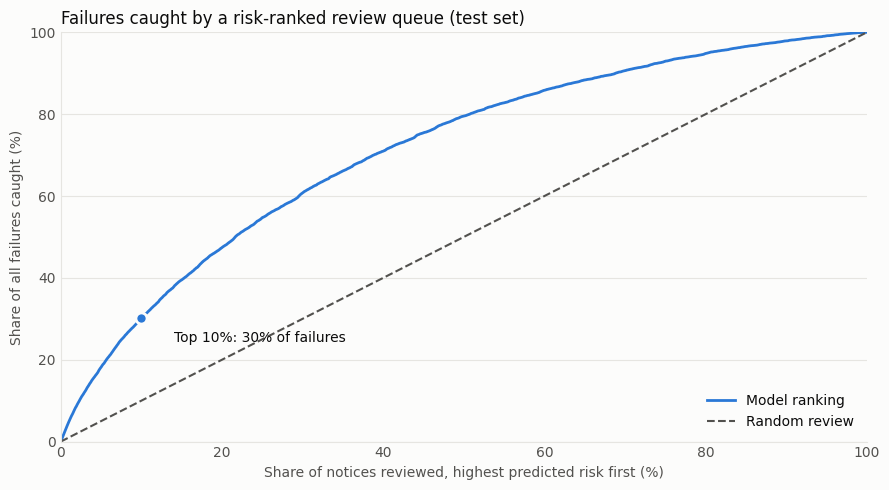

In [6]:
# Chart 1: how many failures a review queue catches, by share of notices reviewed (cumulative gains).
order = np.argsort(-prob_test, kind="stable")
caught = np.cumsum(y_test[order]) / y_test.sum()
share = np.arange(1, len(order) + 1) / len(order)

fig, ax = plt.subplots(figsize=(9, 5), facecolor=SURFACE)
style(ax)
ax.plot(share * 100, caught * 100, color=SERIES, lw=2, label="Model ranking")
ax.plot([0, 100], [0, 100], color=REFERENCE, lw=1.5, ls="--", label="Random review")
x10 = 10; y10 = q10["Recall@k"] * 100
ax.plot([x10], [y10], "o", ms=8, color=SERIES, mec=SURFACE, mew=2)
ax.annotate(f"Top 10%: {y10:.0f}% of failures", (x10, y10), xytext=(14, y10 - 6), color=INK, fontsize=10)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("Share of notices reviewed, highest predicted risk first (%)", color=INK_2)
ax.set_ylabel("Share of all failures caught (%)", color=INK_2)
ax.set_title("Failures caught by a risk-ranked review queue (test set)", color=INK, loc="left")
ax.legend(frameon=False, labelcolor=INK, loc="lower right")
plt.tight_layout(); plt.show()

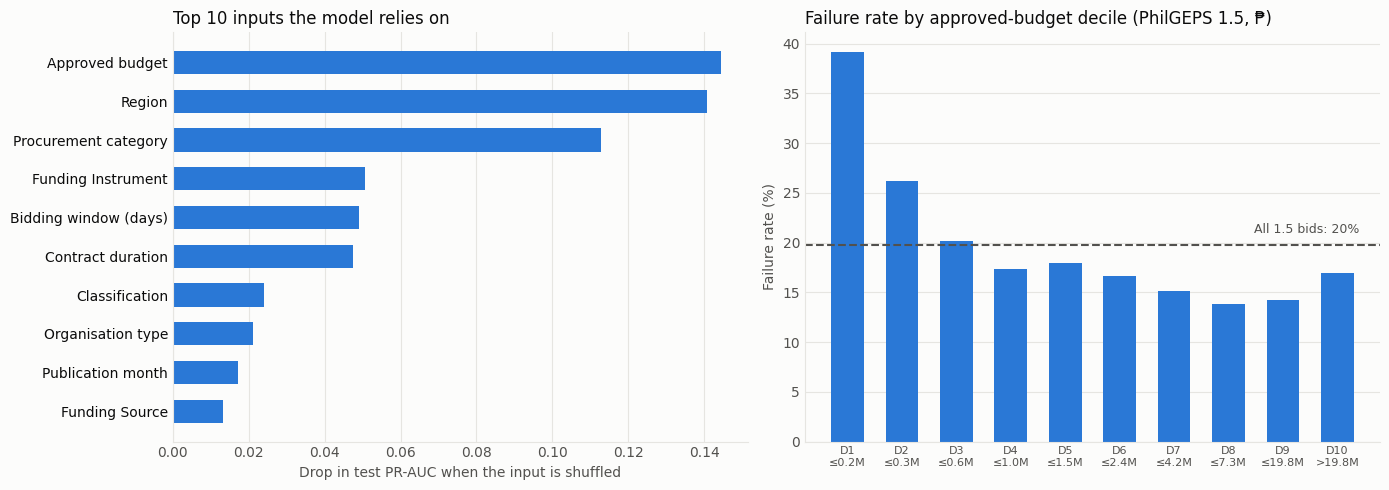

In [7]:
# Chart 2: top drivers of the score. Chart 3: failure rate by approved-budget decile.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor=SURFACE)

top = imp.head(10).iloc[::-1]
ax = axes[0]; style(ax); ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID, lw=0.8)
ax.barh(top.Feature.map(label), top["Mean drop in PR-AUC"], color=SERIES, height=0.6)
ax.set_xlabel("Drop in test PR-AUC when the input is shuffled", color=INK_2)
ax.set_title("Top 10 inputs the model relies on", color=INK, loc="left")
ax.tick_params(axis="y", colors=INK)

ax = axes[1]; style(ax)
ax.bar(dec.budget_decile, dec.failure_rate * 100, color=SERIES, width=0.6)
overall = (dec.failure_rate * dec.bids).sum() / dec.bids.sum() * 100
ax.axhline(overall, color=REFERENCE, ls="--", lw=1.5)
ax.annotate(f"All 1.5 bids: {overall:.0f}%", (10.4, overall), xytext=(10.4, overall + 1.2), ha="right", color=INK_2, fontsize=9)
ticks = [f"D{d}\n≤{m / 1e6:,.1f}M" for d, m in zip(dec.budget_decile, dec["max"])]
ticks[-1] = f"D{dec.budget_decile.iloc[-1]}\n>{dec['max'].iloc[-2] / 1e6:,.1f}M"  # top decile is open-ended
ax.set_xticks(dec.budget_decile, ticks, fontsize=8)
ax.set_ylabel("Failure rate (%)", color=INK_2)
ax.set_title("Failure rate by approved-budget decile (PhilGEPS 1.5, ₱)", color=INK, loc="left")
plt.tight_layout(); plt.show()

## 5. Potential business applications

In [8]:
full_years = bids[bids.published_year.between(2023, 2025)]
per_year = full_years.groupby("published_year").size().mean()
scenarios = pf.queue_metrics(y_test, prob_test, shares=(0.05, 0.10, 0.20))
scenarios["Notices reviewed per year"] = (scenarios["Review share"].str.extract(r"(\d+)")[0].astype(int) / 100 * per_year)
scenarios["Failures in queue per year"] = scenarios["Notices reviewed per year"] * scenarios["Precision@k"]
scenarios["Same effort, random notices"] = scenarios["Notices reviewed per year"] * t["failure rate"]
table = scenarios[["Review share", "Notices reviewed per year", "Failures in queue per year", "Same effort, random notices",
                   "Precision@k", "Recall@k", "Lift@k"]].copy()
for c in ["Notices reviewed per year", "Failures in queue per year", "Same effort, random notices"]:
    table[c] = table[c].map(n)
for c in ["Precision@k", "Recall@k"]:
    table[c] = table[c].map(pct)
table["Lift@k"] = table["Lift@k"].map(lambda v: f"{v:.1f}×")

md(f"""**Review-capacity scenarios.** About {n(per_year)} Public Bidding notices (Closed excluded) were published per year in
2023–2025. If a review team scores every new notice and looks at a fixed share of the riskiest ones, the test-set rates
imply the following yearly workload and catch. This is an illustration: it assumes the test-set rates hold for future notices,
and the out-of-time results (finding 6) suggest they will be somewhat lower without regular retraining.""")
display(table.style.hide(axis="index"))
r10 = scenarios.iloc[1]
md(f"""**Applications**

1. **Pre-award review queue for agencies and BAC secretariats.** Score each notice at publication and flag the riskiest
   {pct(0.10, 0)} for an early check of specifications, budget realism and the bidding window. At that share a reviewer
   meets a likely failure in about {pct(r10["Precision@k"], 0)} of flagged notices, against {pct(t["failure rate"], 0)} at random.
2. **Audit and oversight prioritisation.** Oversight bodies (for example the GPPB or COA) can direct limited audit
   capacity towards agencies, regions and categories whose notices score high, instead of sampling at random.
3. **Agency capacity planning.** Small procurements fail most often (finding 5). Agencies can bundle small purchases,
   use alternative modes where the rules allow, or plan for re-bidding time in their procurement calendars.
4. **Monitoring the PhilGEPS 2.0 transition.** Rising scores or drift in 2.0 notices (finding 8) flag reporting and
   taxonomy issues early, so 2.0 categories can be mapped to 1.5 ones before they distort analytics.
5. **Signal for suppliers (secondary).** A high score warns that a notice is likely to fail, so preparing a bid may be
   wasted effort. It is not a prediction of any supplier's chance of winning.

These uses support human review. The score should not block or automatically cancel any procurement.""")

**Review-capacity scenarios.** About 185,391 Public Bidding notices (Closed excluded) were published per year in
2023–2025. If a review team scores every new notice and looks at a fixed share of the riskiest ones, the test-set rates
imply the following yearly workload and catch. This is an illustration: it assumes the test-set rates hold for future notices,
and the out-of-time results (finding 6) suggest they will be somewhat lower without regular retraining.

Review share,Notices reviewed per year,Failures in queue per year,"Same effort, random notices",Precision@k,Recall@k,Lift@k
top 5%,"9,270","6,739","1,854",72.7%,18.2%,3.6×
top 10%,"18,539","11,227","3,709",60.6%,30.3%,3.0×
top 20%,"37,078","17,591","7,418",47.4%,47.4%,2.4×


**Applications**

1. **Pre-award review queue for agencies and BAC secretariats.** Score each notice at publication and flag the riskiest
   10% for an early check of specifications, budget realism and the bidding window. At that share a reviewer
   meets a likely failure in about 61% of flagged notices, against 20% at random.
2. **Audit and oversight prioritisation.** Oversight bodies (for example the GPPB or COA) can direct limited audit
   capacity towards agencies, regions and categories whose notices score high, instead of sampling at random.
3. **Agency capacity planning.** Small procurements fail most often (finding 5). Agencies can bundle small purchases,
   use alternative modes where the rules allow, or plan for re-bidding time in their procurement calendars.
4. **Monitoring the PhilGEPS 2.0 transition.** Rising scores or drift in 2.0 notices (finding 8) flag reporting and
   taxonomy issues early, so 2.0 categories can be mapped to 1.5 ones before they distort analytics.
5. **Signal for suppliers (secondary).** A high score warns that a notice is likely to fail, so preparing a bid may be
   wasted effort. It is not a prediction of any supplier's chance of winning.

These uses support human review. The score should not block or automatically cancel any procurement.

## 6. Limitations and next steps

In [9]:
cov = diag["label_coverage"]
coverage_all = cov.labelled.sum() / cov.bids.sum()
n20 = int((labelled["Source System"] == "2.0").sum())
md(f"""**Limitations**

1. **Only bids with a posted outcome.** `Closed` notices ({n(cleaning["closed"]) if cleaning["closed"] else "n/a"} line items
   across all modes) are removed, so results do not cover notices that close without a posted outcome. Of the remaining
   bids, {pct(coverage_all)} are labelled.
2. **Random split.** The headline metrics come from a random split; the out-of-time results (finding 6) are the better
   guide to performance on future notices.
3. **Final-state snapshots.** The extracts show each notice as it ended up, so edits made after publication cannot be detected.
4. **PhilGEPS 2.0 is small and different.** {n(n20)} labelled 2.0 bids, with different vocabularies and almost no recorded
   cancellations, so 2.0 results are less certain.
5. **Observational.** The review-queue figures are a historical simulation; they do not show that reviewing a notice
   prevents failure.

**Next steps**

1. Retrain regularly and track performance on newly resolved notices.
2. Map PhilGEPS 2.0 categories and funding sources to the 1.5 vocabulary (or UNSPSC segments).
3. Follow up `Closed` notices as their outcomes are posted.
4. Run a prospective pilot: score notices at publication, record outcomes, and measure reviewer workload and false alarms.""")

**Limitations**

1. **Only bids with a posted outcome.** `Closed` notices (3,015,173 line items
   across all modes) are removed, so results do not cover notices that close without a posted outcome. Of the remaining
   bids, 97.7% are labelled.
2. **Random split.** The headline metrics come from a random split; the out-of-time results (finding 6) are the better
   guide to performance on future notices.
3. **Final-state snapshots.** The extracts show each notice as it ended up, so edits made after publication cannot be detected.
4. **PhilGEPS 2.0 is small and different.** 8,478 labelled 2.0 bids, with different vocabularies and almost no recorded
   cancellations, so 2.0 results are less certain.
5. **Observational.** The review-queue figures are a historical simulation; they do not show that reviewing a notice
   prevents failure.

**Next steps**

1. Retrain regularly and track performance on newly resolved notices.
2. Map PhilGEPS 2.0 categories and funding sources to the 1.5 vocabulary (or UNSPSC segments).
3. Follow up `Closed` notices as their outcomes are posted.
4. Run a prospective pilot: score notices at publication, record outcomes, and measure reviewer workload and false alarms.